# 05 · Validación metodológica de la agrupación exploratoria (20 rutas)

Evidencia ejecutada de `06_scripts/validar_metodologia_clasificacion.py`. **No publica clases ni recomendaciones**: la compuerta sigue cerrada. Informe: `01_documentacion/informe_validacion_metodologica_2026-10-22.md`.

**Cómo leer este notebook.** Las secciones 1–8 conservan el ensayo histórico de cuatro variables del 22 de octubre; la 9 y la 10 documentan el K-means de dos variables y la regla de tres niveles del 22–23 de octubre. La **sección 11 es el experimento vigente de K-means con k = 3 (10 de noviembre de 2026)**: se ejecuta con sus propios datos y no sustituye la clasificación pública.

In [1]:
from pathlib import Path
import subprocess, sys, json
import pandas as pd
from IPython.display import Image, display
RAIZ = Path.cwd().resolve().parent
FECHA = "2026-10-22"
T = RAIZ / "07_resultados/tablas"
r = subprocess.run([sys.executable, str(RAIZ / "06_scripts/validar_metodologia_clasificacion.py"), "--fecha", FECHA],
                   capture_output=True, text=True, cwd=RAIZ)
assert r.returncode == 0, r.stderr[-2000:]
resumen = json.loads((T / f"validacion_resumen_{FECHA}.json").read_text(encoding="utf-8"))
print(resumen["versiones"], resumen["habilitacion"])
assert not (T / "niveles_esfuerzo_finales.csv").exists() and not (T / "validacion_modelo_final.json").exists()
def tabla(n): return pd.read_csv(T / f"validacion_{n}_{FECHA}.csv")

{'pandas': '3.0.5', 'numpy': '2.5.3', 'sklearn': '1.9.1'} NO: este resumen no es validacion_modelo_final.json ni habilita recomendaciones


## 1. Integridad y reproducción del ensayo previo

In [2]:
i = resumen["integridad"]; assert i["n_rutas"] == 20 and i["ids_unicos"] and i["valores_faltantes"] == 0
print({k: v for k, v in i.items() if k != "rutas_por_destino"})
rep = tabla("reproduccion_previa"); assert rep["coincide"].all(); rep

{'n_rutas': 20, 'ids_unicos': True, 'valores_faltantes': 0, 'media_estandarizada_max_abs': 3.4416913763379854e-16, 'desv_estandarizada_min_max': [1.0, 1.0], 'destinos_distintos': 13}


,k,silueta_nueva,silueta_previa,inercia_nueva,inercia_previa,ari_asignacion_vs_previa,coincide
0,2,0.4477,0.4477,44.0976,44.0976,1.0,True
1,3,0.3203,0.3203,30.8581,30.8581,1.0,True
2,4,0.3353,0.3353,23.1229,23.1229,1.0,True


## 2. K-means k = 2, 3, 4

In [3]:
tabla("kmeans_resumen")

,k,silueta_mejor,silueta_semillas_min,silueta_semillas_max,inercia_mejor,tamanos,tamano_minimo,ari_semillas_min,ari_semillas_media,ari_entre_pares_min,semillas_que_reproducen_mejor,ari_ward
0,2,0.4477,0.4477,0.4477,44.0976,4/16,4,1.0000,1.0000,1.0000,50/50,1.0000
1,3,0.3203,0.3203,0.3213,30.8581,3/6/11,3,0.4620,0.9354,0.4620,44/50,0.7474
2,4,0.3353,0.3226,0.3353,23.1229,2/2/8/8,2,0.3345,0.8348,0.3345,33/50,0.4471


In [4]:
tabla("centroides_unidades_originales").query("k == 2").T

,0,1
k,2,2
grupo_ordenado_por_ascenso,0,1
n,16,4
rutas,R004|R008|R011|R013|R015|R016|R017|R018|R019|R...,R001|R003|R006|R022
distancia_total_km_media,2.73,6.67
distancia_total_km_mediana,1.9,6.36
distancia_total_km_min,0.52,4.36
distancia_total_km_max,6.63,9.61
ascenso_total_m_media,167.35,653.24
ascenso_total_m_mediana,159.52,669.57


## 3. ¿Qué explica la partición 4/16?

,variable_sola,ari_vs_k2_base,silueta_1d
0,distancia_total_km,0.3286,0.6577
1,ascenso_total_m,1.0000,0.6686
2,elevacion_max_m,-0.0071,0.7018
3,pendiente_media_abs_pct,0.3676,0.6707
4,pendiente_p95_abs_pct,0.0551,0.5140
5,indice_naismith_h (referencia a priori),0.3286,0.6617


,variable,minimo_grupo_mayor,maximo_grupo_menor,separacion_total
0,distancia_total_km,4.36,6.63,False
1,ascenso_total_m,448.98,339.04,True
2,elevacion_max_m,3082.38,3549.29,False
3,pendiente_media_abs_pct,12.00,23.19,False
4,pendiente_p95_abs_pct,43.67,72.92,False
5,indice_naismith_h,1.74,1.89,False


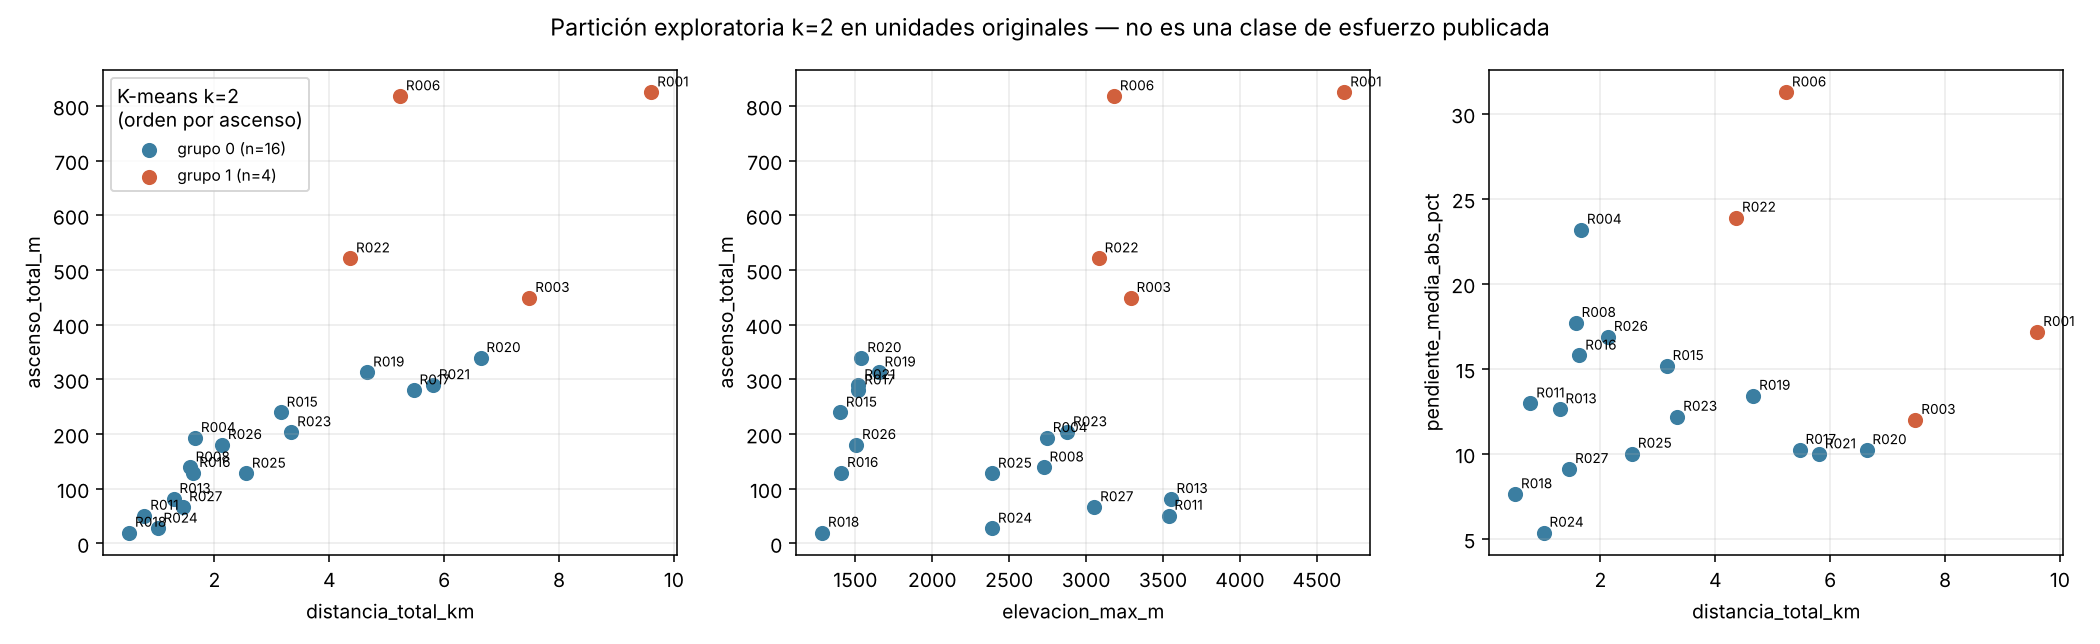

In [5]:
display(tabla("origen_k2_variable_sola")); display(tabla("separacion_k2_por_variable"))
display(Image(str(RAIZ / f"07_resultados/figuras/validacion_k2_unidades_originales_{FECHA}.png")))

## 4. Estabilidad al retirar una ruta

In [6]:
l = tabla("estabilidad_retirando_una_ruta"); display(l.groupby("k")["ari_vs_base"].agg(["min", "median"])); l[l.ari_vs_base < 1]

,min,median
k,,
2,1.0000,1.0000
3,0.4321,0.8146


,k,ruta_retirada,ari_vs_base,n_comun
23,3,R006,0.9152,19
25,3,R011,0.8146,19
26,3,R013,0.8146,19
28,3,R016,0.7179,19
29,3,R017,0.4575,19
30,3,R018,0.5611,19
31,3,R019,0.4575,19
32,3,R020,0.4575,19
33,3,R021,0.4575,19
36,3,R024,0.8146,19


## 5. DBSCAN como contraste (ruido ≠ dificultad)

9 configuraciones con >= 2 grupos; 9 con R001, R003, R006 y R022 como ruido


,eps,min_samples,n_grupos,n_ruido,cobertura_pct,tamanos_grupos,silueta_sin_ruido,ari_estabilidad_loo_min,rutas_ruido
0,0.50,2,3,13,35.0,2/2/3,0.8438,1.0000,R001|R003|R004|R006|R008|R015|R018|R019|R022|R...
1,0.75,2,3,11,45.0,2/3/4,0.6945,1.0000,R001|R003|R004|R006|R008|R018|R022|R023|R024|R...
2,1.00,2,3,5,75.0,2/6/7,0.3852,0.7632,R001|R003|R006|R018|R022
3,1.25,2,2,5,75.0,7/8,0.3966,0.7668,R001|R003|R006|R018|R022
4,1.50,2,1,4,80.0,16,NaN,0.0000,R001|R003|R006|R022
5,2.00,2,1,1,95.0,19,NaN,0.0000,R001
6,0.50,3,1,17,15.0,3,NaN,1.0000,R001|R003|R004|R006|R008|R011|R013|R015|R016|R...
7,0.75,3,2,13,35.0,3/4,0.6365,1.0000,R001|R003|R004|R006|R008|R011|R013|R018|R022|R...
8,1.00,3,2,7,65.0,6/7,0.4663,0.7179,R001|R003|R004|R006|R008|R018|R022
9,1.25,3,2,5,75.0,7/8,0.3966,1.0000,R001|R003|R006|R018|R022


,eps,min_samples,k_kmeans,n_grupos_dbscan,rutas_comparadas,rutas_fuera_por_ruido,ari_solo_no_ruido,kmeans_grupos_en_no_ruido,comparable
1,0.50,2,3,3,7,13,0.5882,2,True
3,0.75,2,3,3,9,11,0.4156,2,True
5,1.00,2,3,3,15,5,0.2862,2,True
7,1.25,2,3,2,15,5,0.5063,2,True
15,0.75,3,3,2,7,13,0.4324,2,True
17,1.00,3,3,2,13,7,0.4348,2,True
19,1.25,3,3,2,15,5,0.5063,2,True
29,1.00,4,3,2,12,8,0.3917,2,True
31,1.25,4,3,2,14,6,0.4730,2,True


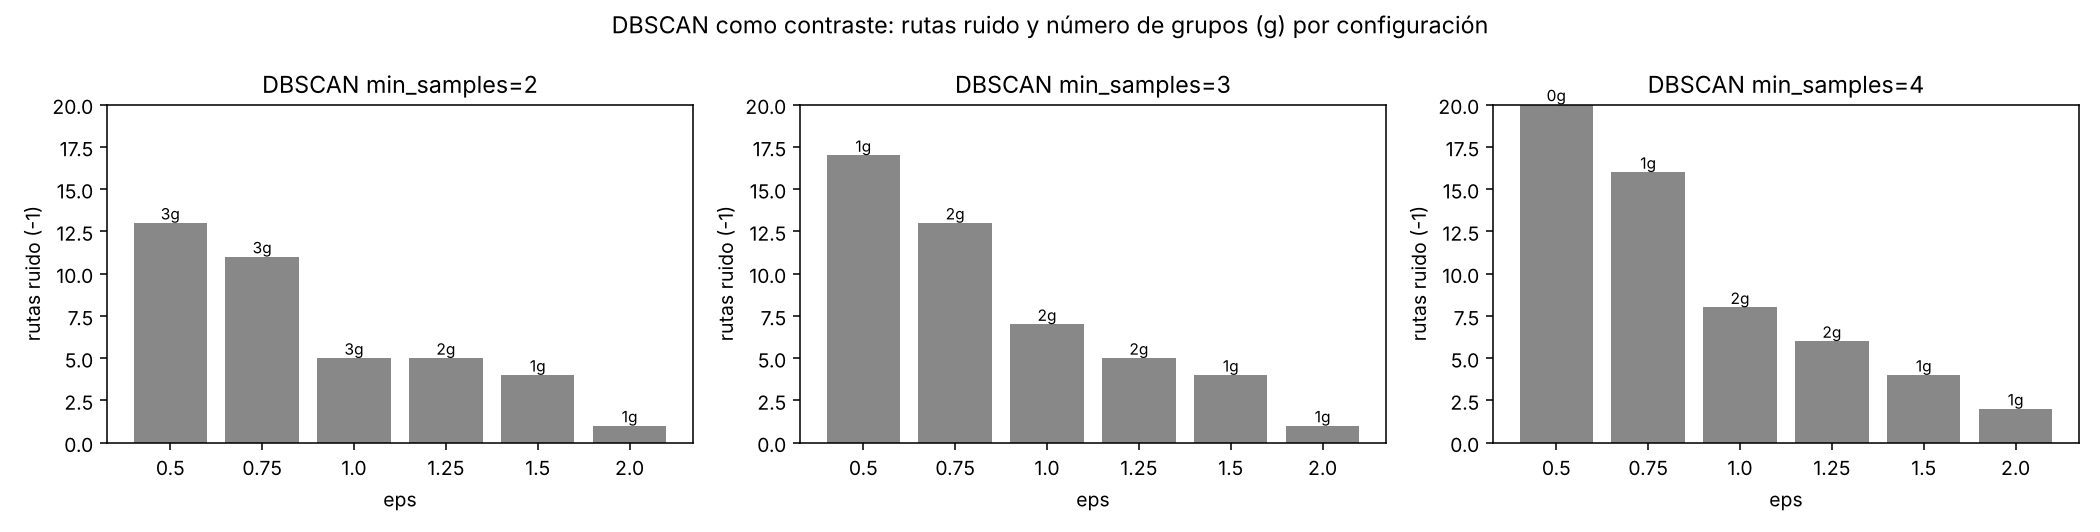

In [7]:
d = tabla("dbscan_malla"); display(d.drop(columns=["ruido_incluye_R001_R003_R006_R022"]))
multi = d[d.n_grupos >= 2]; print(len(multi), "configuraciones con >= 2 grupos;", int(multi.ruido_incluye_R001_R003_R006_R022.sum()), "con R001, R003, R006 y R022 como ruido")
display(tabla("dbscan_vs_kmeans").query("comparable"))
display(Image(str(RAIZ / f"07_resultados/figuras/validacion_dbscan_ruido_{FECHA}.png")))

## 6. Sensibilidad

In [8]:
tabla("sensibilidad").drop(columns=["variables"]).query("k == 2")

,escenario,k,n_rutas,silueta,tamanos,ari_vs_base_en_comunes,n_comunes,ari_semillas_min,grupo_mayor_ascenso_k2
0,base,2,20,0.4477,4/16,1.0000,20,1.0000,R001|R003|R006|R022
2,sin_distancia,2,20,0.5162,3/17,0.7644,20,1.0000,R001|R006|R022
4,sin_ascenso,2,20,0.3765,4/16,1.0000,20,0.5759,R001|R003|R006|R022
6,sin_altitud_maxima,2,20,0.4760,4/16,1.0000,20,0.7644,R001|R003|R006|R022
8,altitud_peso_0.5,2,20,0.4662,4/16,1.0000,20,1.0000,R001|R003|R006|R022
10,altitud_peso_2,2,20,0.3958,10/10,0.1307,20,1.0000,R001|R003|R004|R006|R008|R011|R013|R022|R023|R027
12,con_pendiente_p95,2,20,0.3781,5/15,0.7852,20,1.0000,R001|R003|R004|R006|R022
14,sin_R026,2,19,0.4372,4/15,1.0000,19,1.0000,R001|R003|R006|R022
16,sin_R027,2,19,0.4405,4/15,1.0000,19,0.7578,R001|R003|R006|R022
18,sin_R026_ni_R027,2,18,0.4282,4/14,1.0000,18,1.0000,R001|R003|R006|R022


In [9]:
tabla("sensibilidad").drop(columns=["variables"]).query("k == 3")

,escenario,k,n_rutas,silueta,tamanos,ari_vs_base_en_comunes,n_comunes,ari_semillas_min,grupo_mayor_ascenso_k2
1,base,3,20,0.3203,3/6/11,1.0000,20,0.4620,NaN
3,sin_distancia,3,20,0.3731,3/8/9,0.4125,20,0.6565,NaN
5,sin_ascenso,3,20,0.3157,4/8/8,0.4620,20,0.6970,NaN
7,sin_altitud_maxima,3,20,0.4345,3/5/12,0.8247,20,1.0000,NaN
9,altitud_peso_0.5,3,20,0.3948,3/5/12,0.8247,20,1.0000,NaN
11,altitud_peso_2,3,20,0.4374,4/8/8,0.4620,20,1.0000,NaN
13,con_pendiente_p95,3,20,0.2588,3/5/12,0.8247,20,0.2304,NaN
15,sin_R026,3,19,0.3400,3/6/10,1.0000,19,1.0000,NaN
17,sin_R027,3,19,0.3238,3/5/11,0.8146,19,0.8146,NaN
19,sin_R026_ni_R027,3,18,0.3245,3/6/9,1.0000,18,0.8030,NaN


## 7. Criterios fijados antes de los resultados

In [10]:
c = tabla("criterios_decision"); print(int(c.cumple.sum()), "de", len(c), "criterios cumplidos"); c

6 de 7 criterios cumplidos


,criterio,valor,umbral_previo,cumple
0,C1 estabilidad entre semillas (ARI mín),1.0000,>= 0.9,True
1,C2 concordancia con Ward (ARI),1.0000,>= 0.9,True
2,C3 estabilidad al retirar una ruta (ARI mín),1.0000,>= 0.7,True
3,C4 tamaño mínimo de grupo,4.0000,>= 3,True
4,C5 silueta k=2,0.4477,>= 0.4,True
5,C6 sensibilidad a rutas/pesos/destinos (ARI mí...,0.1307,>= 0.7,False
6,C7 sensibilidad a cambio de variables (ARI mín...,0.7644,>= 0.7,True


**Decisión:** ver informe. k = 3 y 4 inestables; k = 2 equivale a un umbral de ascenso acumulado (339–449 m), no a altitud ni a un índice de tiempo; DBSCAN no lo confirma. La clasificación de esfuerzo sigue exploratoria y `estado_clasificacion` mantiene 0 rutas habilitadas.

## 8. Indicador continuo de esfuerzo de referencia (HEN)

Definición explícita: `HEN = distancia_total_km / 5 + ascenso_total_m / 600` (regla de Naismith). Son **horas-equivalentes estimadas de referencia, no tiempos medidos**, sin clases «fácil/difícil», sin recomendaciones. La altitud queda como advertencia separada y no entra en la fórmula. Informe: `01_documentacion/informe_indicador_esfuerzo_2026-10-22.md`.

In [11]:
r2 = subprocess.run([sys.executable, str(RAIZ / "06_scripts/calcular_indicador_esfuerzo.py"), "--fecha", FECHA],
                    capture_output=True, text=True, cwd=RAIZ)
assert r2.returncode == 0, r2.stderr[-2000:]
ind = json.loads((T / f"indicador_resumen_{FECHA}.json").read_text(encoding="utf-8"))
print(ind["definicion"], "|", ind["naturaleza"], "|", ind["altitud"])
assert not (T / "niveles_esfuerzo_finales.csv").exists() and not (T / "validacion_modelo_final.json").exists()
def ti(n): return pd.read_csv(T / f"{n}_{FECHA}.csv")
ti("indicador_esfuerzo")

HEN = distancia_total_km / V + ascenso_total_m / R (regla de Naismith) | horas-equivalentes estimadas de referencia; no son tiempos medidos ni clases | advertencia separada; no entra en el indicador


,id_ruta,id_destino,tipo_recorrido,distancia_total_km,ascenso_total_m,componente_distancia_h,componente_ascenso_h,hen_horas_equivalentes,posicion_esfuerzo,km_esfuerzo,tobler_h_contraste,posicion_tobler,hen_con_ascenso_mediana3_h,hen_con_ascenso_mediana5_h,hen_con_ascenso_crudo_h,altitud_maxima_advertencia_m
0,R001,D001,ida_y_vuelta,9.607,824.839,1.9214,1.374732,3.296132,1,17.85539,4.039794,2,3.296132,3.180432,3.689902,4678.573
1,R006,D006,ida_y_vuelta,5.232,817.832,1.0464,1.363053,2.409453,2,13.41032,4.357716,1,2.409453,2.377480,2.485647,3181.260
2,R003,D003,ida_y_vuelta,7.484,448.981,1.4968,0.748302,2.245102,3,11.97381,2.708251,3,2.245102,2.168025,2.587972,3289.859
3,R020,D010,ida_y_vuelta,6.633,339.038,1.3266,0.565063,1.891663,4,10.02338,1.765906,5,1.891663,1.868507,2.048203,1539.781
4,R022,D012,ida_y_vuelta,4.363,521.309,0.8726,0.868848,1.741448,5,9.57609,2.025869,4,1.741448,1.741448,1.786048,3082.381
5,R021,D010,ida_y_vuelta,5.805,289.526,1.1610,0.482543,1.643543,6,8.70026,1.512366,7,1.643543,1.619023,1.746203,1520.280
6,R017,D010,ida_y_vuelta,5.469,279.978,1.0938,0.466630,1.560430,7,8.26878,1.421230,8,1.560430,1.529090,1.679577,1520.280
7,R019,D011,ida_y_vuelta,4.661,312.715,0.9322,0.521192,1.453392,8,7.78815,1.611000,6,1.453392,1.326882,2.158082,1651.464
8,R015,D010,ida_y_vuelta,3.155,239.270,0.6310,0.398783,1.029783,9,5.54770,1.327977,9,1.029783,0.996140,1.257363,1400.471
9,R023,D013,ida_y_vuelta,3.339,203.427,0.6678,0.339045,1.006845,10,5.37327,1.029761,11,1.006845,0.972948,1.358035,2876.723


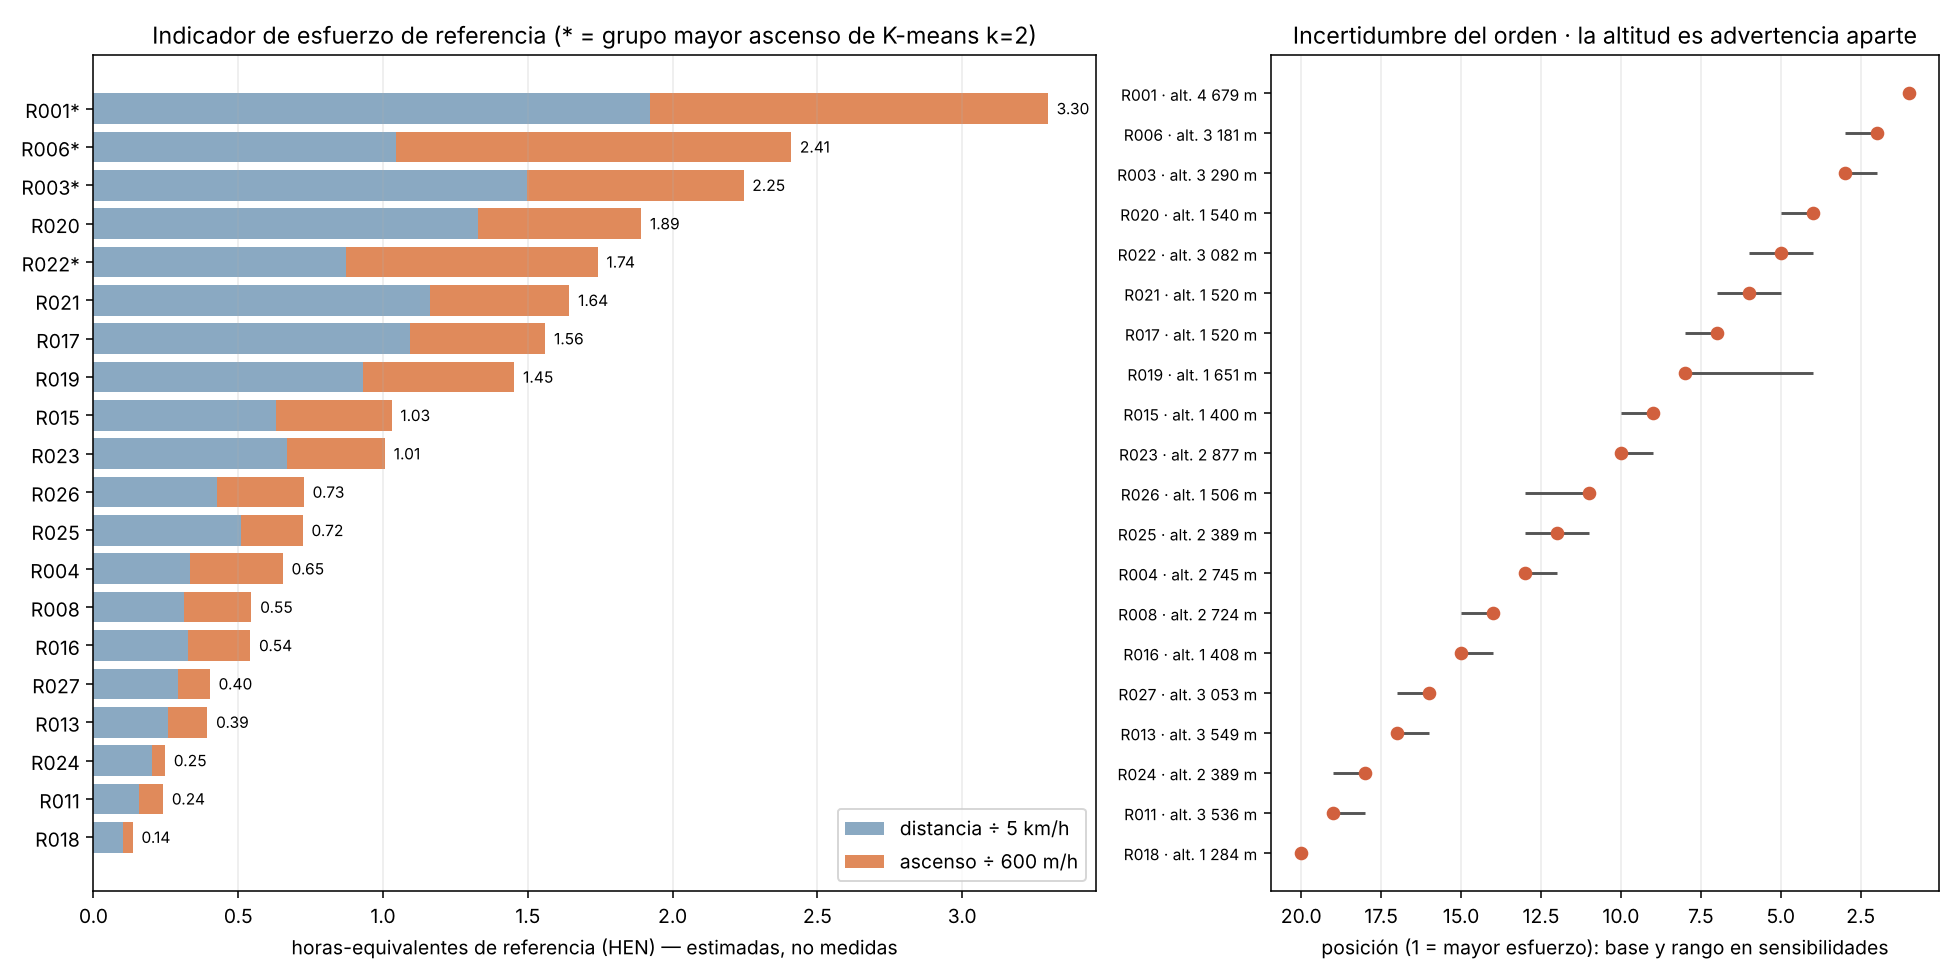

In [12]:
display(Image(str(RAIZ / f"07_resultados/figuras/indicador_esfuerzo_{FECHA}.png")))

### 8.1 Formulaciones alternativas y sensibilidad a parámetros (V, R)

In [13]:
display(ti("indicador_formulaciones")); p = ti("indicador_sensibilidad_parametros"); print(len(p), "combinaciones V x R; Spearman mínimo", p.spearman_vs_base.min().round(4), "; desplazamiento máximo", p.max_desplazamiento_posiciones.max(), "posiciones"); p

20 combinaciones V x R; Spearman mínimo 0.9925 ; desplazamiento máximo 1.0 posiciones


,formulacion,spearman_vs_base
0,"Naismith (base, 5 km/h; 600 m/h)",1.000000
1,km-esfuerzo (km + m/100),0.998496
2,Tobler sobre el perfil (contraste),0.980451
3,solo distancia,0.968421
4,solo ascenso,0.975940
5,altitud máxima (variable ajena al indicador),0.184349


,v_kmh,r_m_h,spearman_vs_base,max_desplazamiento_posiciones,top5_igual_a_base
0,4.0,300.0,0.995489,1.0,True
1,4.0,400.0,0.998496,1.0,True
2,4.0,500.0,1.000000,0.0,True
3,4.0,600.0,0.998496,1.0,True
4,4.0,800.0,0.992481,1.0,False
5,4.5,300.0,0.993985,1.0,True
6,4.5,400.0,0.996992,1.0,True
7,4.5,500.0,1.000000,0.0,True
8,4.5,600.0,0.998496,1.0,True
9,4.5,800.0,0.993985,1.0,False


### 8.2 Límites del DEM: ascenso filtrado frente a crudo y ruido aleatorio adicional

El ascenso depende del filtro: el perfil crudo suma entre 1,05 y 2,35 veces el ascenso de la mediana de 3 puntos. El orden es casi invariante, pero **los valores absolutos de horas no lo son**.

In [14]:
display(ti("indicador_sensibilidad_dem")); display(ti("indicador_dem_perfiles").round(2)); mc = ti("indicador_dem_montecarlo"); display(mc.groupby("sigma_dem_m").apply(lambda g: (g.posicion_p95 - g.posicion_p05).max()).rename("amplitud_max_p05_p95_posiciones"))

,ascenso_usado,spearman_vs_base,max_desplazamiento_posiciones,mediana_razon_ascenso_vs_base
0,mediana3 (base),1.000000,0.0,1.000000
1,mediana5,0.998496,1.0,0.929166
2,crudo sin filtrar,0.978947,4.0,1.517602


,id_ruta,ascenso_mediana3_m,ascenso_mediana5_m,ascenso_crudo_m,tobler_h,paso_muestreo_mediano_m,razon_crudo_sobre_mediana3
0,R001,824.84,755.42,1061.10,4.04,29.84,1.29
1,R003,448.98,402.73,654.70,2.71,29.94,1.46
2,R004,192.82,186.25,227.46,1.03,29.70,1.18
3,R006,817.83,798.65,863.55,4.36,29.73,1.06
4,R008,138.99,138.99,231.19,0.67,29.08,1.66
5,R011,50.67,42.16,111.54,0.25,27.91,2.20
6,R013,81.34,71.88,151.13,0.45,29.28,1.86
7,R015,239.27,219.08,375.82,1.33,29.76,1.57
8,R016,128.93,128.93,186.51,0.53,29.18,1.45
9,R017,279.98,261.17,351.47,1.42,29.72,1.26


sigma_dem_m
1.0    1.0
2.0    1.0
4.0    2.0
Name: amplitud_max_p05_p95_posiciones, dtype: float64

### 8.3 Intervalos de posición (todas las sensibilidades)

In [15]:
ti("indicador_intervalos_posicion")

,id_ruta,posicion_base,rango_parametros_min,rango_parametros_max,rango_dem_min,rango_dem_max,rango_montecarlo_p05_min,rango_montecarlo_p95_max,posicion_min_global,posicion_max_global,amplitud_posiciones
0,R001,1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
1,R006,2,2.0,3.0,2.0,3.0,2.0,2.0,2.0,3.0,1.0
2,R003,3,2.0,3.0,2.0,3.0,3.0,3.0,2.0,3.0,1.0
3,R020,4,4.0,5.0,4.0,5.0,4.0,4.0,4.0,5.0,1.0
4,R022,5,4.0,6.0,5.0,6.0,5.0,5.0,4.0,6.0,2.0
5,R021,6,5.0,6.0,6.0,7.0,6.0,6.0,5.0,7.0,2.0
6,R017,7,7.0,7.0,7.0,8.0,7.0,7.0,7.0,8.0,1.0
7,R019,8,8.0,8.0,4.0,8.0,8.0,8.0,4.0,8.0,4.0
8,R015,9,9.0,10.0,9.0,10.0,9.0,10.0,9.0,10.0,1.0
9,R023,10,9.0,10.0,9.0,10.0,9.0,10.0,9.0,10.0,1.0


### 8.4 Contraste con K-means k = 2 (sin convertir el orden en clases)

In [16]:
c = ind["contraste_kmeans_k2"]; print(json.dumps(c, ensure_ascii=False, indent=1)); display(ti("indicador_brechas").head(5)); ti("indicador_contraste_kmeans")

{
 "spearman_hen_vs_puntaje_kmeans_k2": 0.8390977443609022,
 "auc_hen_grupo_mayor_ascenso_vs_resto": 0.984375,
 "mejor_umbral_hen_h": 1.7414483333333335,
 "ari_mejor_umbral_vs_kmeans_k2": 0.7852468768590125,
 "rutas_del_grupo_menor_con_hen_igual_o_mayor_que_la_minima_del_grupo_mayor": [
  "R020"
 ],
 "ari_kmeans_1d_sobre_hen_vs_kmeans_k2": 0.3286219081272085,
 "grupo_mayor_kmeans_k2": [
  "R001",
  "R003",
  "R006",
  "R022"
 ],
 "mayor_brecha_consecutiva_h": 0.8866783333333332,
 "mayor_brecha_entre": "1-2",
 "rango_hen_h": [
  0.13576833333333335,
  3.2961316666666667
 ]
}


,entre_posiciones,brecha_h
0,1-2,0.886678
1,8-9,0.423608
2,3-4,0.353438
3,10-11,0.280170
4,2-3,0.164352


,id_ruta,grupo_kmeans_k2_orden_por_ascenso,puntaje_kmeans_eje_centroides,hen_horas_equivalentes
0,R001,1,2.976794,3.296132
1,R003,1,0.500973,2.245102
2,R004,0,-0.817734,0.653968
3,R006,1,2.389590,2.409453
4,R008,0,-1.377419,0.545657
5,R011,0,-1.724580,0.240653
6,R013,0,-1.558057,0.393368
7,R015,0,-1.588861,1.029783
8,R016,0,-2.145394,0.541687
9,R017,0,-1.315294,1.560430


**Lectura:** el orden continuo es estable; K-means k = 2 equivale en lo esencial al extremo superior del orden (con R020 intercalada), pero el orden continuo no muestra un corte natural en ese punto. Ver la propuesta de decisión compartida en el informe.

## 9. Clasificación K-means de exigencia física relativa

Las secciones anteriores documentan el modelo inicial de cuatro variables y el indicador continuo. Esta revisión usa **distancia total y ascenso total estandarizados** como variables del K-means principal, deja altitud y pendiente fuera del ajuste, compara k=2,3,4 y marca rutas sensibles. Las clases son relativas a las 20 rutas estudiadas, no equivalen a dificultad técnica ni seguridad. Informe: `01_documentacion/informe_modelo_kmeans_fisico_2026-10-22.md`.

In [17]:
r = subprocess.run([sys.executable, str(RAIZ / '06_scripts/evaluar_kmeans_esfuerzo.py'), '--fecha', FECHA],
                   capture_output=True, text=True, cwd=RAIZ)
assert r.returncode == 0, r.stderr[-2000:]
km_resumen = pd.read_csv(T / f'modelo_kmeans_fisico_resumen_{FECHA}.csv')
km_asignaciones = pd.read_csv(T / f'modelo_kmeans_fisico_asignaciones_{FECHA}.csv')
assert len(km_asignaciones) == 20 and km_asignaciones.id_ruta.is_unique
assert km_resumen.set_index('k').loc[2, 'tamanos'] == '8/12'
print(r.stdout.strip())
display(km_asignaciones[['id_ruta', 'distancia_total_km', 'ascenso_total_m',
                         'etiqueta_descriptiva', 'sensible_a_parametros']])

k                          variables  n_rutas  silueta  inercia tamanos  ari_semillas_min  ari_ward
 2 distancia_total_km|ascenso_total_m       20   0.5919  12.9118    8/12            1.0000    1.0000
 3 distancia_total_km|ascenso_total_m       20   0.5895   6.1769  2/6/12            1.0000    0.9246
 4 distancia_total_km|ascenso_total_m       20   0.4354   4.5064 2/5/6/7            0.5111    0.5111
Rutas sensibles: 4/20


,id_ruta,distancia_total_km,ascenso_total_m,etiqueta_descriptiva,sensible_a_parametros
0,R001,9.607,824.839,Mayor esfuerzo físico estimado relativo,no
1,R003,7.484,448.981,Mayor esfuerzo físico estimado relativo,no
2,R004,1.663,192.821,Menor esfuerzo físico estimado relativo,no
3,R006,5.232,817.832,Mayor esfuerzo físico estimado relativo,no
4,R008,1.570,138.994,Menor esfuerzo físico estimado relativo,no
5,R011,0.781,50.672,Menor esfuerzo físico estimado relativo,no
6,R013,1.289,81.341,Menor esfuerzo físico estimado relativo,no
7,R015,3.155,239.270,Menor esfuerzo físico estimado relativo,no
8,R016,1.634,128.932,Menor esfuerzo físico estimado relativo,no
9,R017,5.469,279.978,Mayor esfuerzo físico estimado relativo,si


## 10. Clasificación principal en tres niveles

La salida final del plan conserva **Fácil, Moderada y Difícil** mediante una regla física explícita inspirada en la cantidad de esfuerzo de MIDE. No se fuerza K-means a producir tres grupos: las secciones anteriores se conservan como contraste exploratorio. La regla combina distancia, ascenso y descenso, declara sus supuestos y evalúa sensibilidad a velocidad horizontal y filtrado del DEM. No representa el MIDE completo, dificultad técnica, seguridad ni recomendación.

In [18]:
FECHA_NIVELES = '2026-10-23'
r = subprocess.run([sys.executable, str(RAIZ / '06_scripts/clasificar_dificultad_fisica.py'), '--fecha', FECHA_NIVELES],
                   capture_output=True, text=True, cwd=RAIZ)
assert r.returncode == 0, r.stderr[-2000:]
clasificacion_3 = pd.read_csv(T / f'clasificacion_dificultad_fisica_{FECHA_NIVELES}.csv')
sensibilidad_3 = pd.read_csv(T / f'clasificacion_dificultad_fisica_sensibilidad_{FECHA_NIVELES}.csv')
assert len(clasificacion_3) == 20 and clasificacion_3.id_ruta.is_unique
assert clasificacion_3['dificultad_fisica_estimada'].value_counts().to_dict() == {'Moderada': 10, 'Fácil': 8, 'Difícil': 2}
assert set(clasificacion_3.loc[clasificacion_3['sensible_a_supuestos'] == 'si', 'id_ruta']) == {'R003', 'R004', 'R008', 'R019', 'R025', 'R026'}
print(r.stdout.strip())
display(clasificacion_3[['id_ruta', 'nombre_ruta', 'distancia_total_km', 'desnivel_positivo_total_m', 'desnivel_negativo_total_m',
                         'horas_marcha_efectiva_estimadas', 'dificultad_fisica_estimada', 'sensible_a_supuestos']])

id_ruta  horas_marcha_efectiva_estimadas dificultad_fisica_estimada sensible_a_supuestos
   R018                           0.1697                      Fácil                   no
   R011                           0.3088                      Fácil                   no
   R024                           0.3092                      Fácil                   no
   R013                           0.5000                      Fácil                   no
   R027                           0.5025                      Fácil                   no
   R016                           0.7415                      Fácil                   no
   R008                           0.7754                      Fácil                   si
   R025                           0.9035                      Fácil                   si
   R004                           1.0113                   Moderada                   si
   R026                           1.0168                   Moderada                   si
   R023              

,id_ruta,nombre_ruta,distancia_total_km,desnivel_positivo_total_m,desnivel_negativo_total_m,horas_marcha_efectiva_estimadas,dificultad_fisica_estimada,sensible_a_supuestos
0,R018,Sendero de la Cascada de Maquipucuna,0.515,19.661,19.661,0.1697,Fácil,no
1,R011,Sendero Masked Trogon,0.781,50.672,50.672,0.3088,Fácil,no
2,R024,Cerro de la Luz - sendero directo al mirador,1.011,27.112,27.112,0.3092,Fácil,no
3,R013,Sendero Oso de Anteojos,1.289,81.341,81.341,0.5000,Fácil,no
4,R027,Sendero del Viento - sector recreativo Moraspungo,1.457,66.371,66.371,0.5025,Fácil,no
5,R016,Mindo Hermit Trail - Mirador,1.634,128.932,128.932,0.7415,Fácil,no
6,R008,Sendero de ascenso al Pondoña,1.570,138.994,138.994,0.7754,Fácil,si
7,R025,Cerro de la Luz - sendero superior al mirador,2.550,127.660,127.660,0.9035,Fácil,si
8,R004,Circuito Pondoña (Sendero Pondoña),1.663,192.821,192.821,1.0113,Moderada,si
9,R026,Sendero Tarabita - Cascada Guarumos,2.133,180.045,180.045,1.0168,Moderada,si


## 11. Experimento K-means con k = 3 (10 de noviembre de 2026)

Pregunta: ¿puede K-means con k = 3 sobre distancia total y ascenso total producir grupos físicos coherentes y suficientemente estables para sustentar los nombres Fácil, Moderada y Difícil? El diseño y los criterios de aceptación C1–C5 se fijaron **antes** de ejecutar (`01_documentacion/diseno_experimento_kmeans_k3_2026-11-10.md`); los resultados y su interpretación están en `01_documentacion/informe_kmeans_k3_dificultad_2026-11-10.md`. K-means es aquí un contraste exploratorio: la clasificación pública sigue siendo la regla de esfuerzo adaptada de MIDE (sección 10). Los grupos describen esfuerzo físico estimado relativo a estas 20 rutas; no miden seguridad, dificultad técnica, acceso, clima ni aptitud personal.

### 11.1 Integridad y reproducción

In [19]:
import importlib.util, tempfile
FECHA_K3 = "2026-11-10"
spec = importlib.util.spec_from_file_location("kmeans_k3", RAIZ / "06_scripts/evaluar_kmeans_k3_dificultad.py")
k3 = importlib.util.module_from_spec(spec); spec.loader.exec_module(k3)
def t3(n): return pd.read_csv(T / f"kmeans_k3_{n}_{FECHA_K3}.csv")
par = json.loads((T / f"kmeans_k3_parametros_{FECHA_K3}.json").read_text(encoding="utf-8"))
# Recalcula todo el experimento en un directorio temporal: no sobrescribe los resultados archivados.
with tempfile.TemporaryDirectory() as tmp:
    nuevo = k3.ejecutar(FECHA_K3, Path(tmp))
asig = t3("asignaciones")
assert len(asig) == 20 and asig.id_ruta.is_unique and not asig.isna().any().any()
assert asig.grupo_k3.tolist() == nuevo["salidas"]["asignaciones"].grupo_k3.tolist(), "las asignaciones archivadas no se reproducen"
assert nuevo["decision"] == par["decision_reglas_a_priori"] == "B"
dataset = pd.read_csv(T / "dataset_clasificacion_rutas.csv")
print("Rutas procesadas:", len(dataset), "| elegibles:", int(dataset.estado_modelado.eq("elegible_actual").sum()),
      "| no elegibles:", int(dataset.estado_modelado.ne("elegible_actual").sum()))
print("Variables:", par["variables"], "| semillas 0-49, n_init =", par["n_init"], "| versiones:", par["versiones"])
print("Correlación distancia-ascenso:", par["correlacion_distancia_ascenso"])
print("Asignaciones archivadas reproducidas exactamente: sí")

Rutas procesadas: 27 | elegibles: 20 | no elegibles: 7
Variables: ['distancia_total_km', 'ascenso_total_m'] | semillas 0-49, n_init = 10 | versiones: {'python': '3.13.16', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}
Correlación distancia-ascenso: {'pearson': 0.8289, 'spearman': 0.9263}
Asignaciones archivadas reproducidas exactamente: sí


### 11.2 Comparación k = 2, 3 y 4 (mismas 20 rutas)

In [20]:
m3 = t3("metricas")
assert m3.set_index("k").loc[3, "tamanos"] == "12/6/2"
m3[["k", "tamanos", "inercia", "silueta", "ari_semillas_min", "n_semillas_con_misma_particion", "ari_ward"]]

,k,tamanos,inercia,silueta,ari_semillas_min,n_semillas_con_misma_particion,ari_ward
0,2,12/8,12.9118,0.5919,1.0000,50,1.0000
1,3,12/6/2,6.1769,0.5895,1.0000,50,0.9246
2,4,7/5/6/2,4.5064,0.4354,0.5111,40,0.5111


### 11.3 Los tres grupos de k = 3

El orden físico de los grupos usa la suma de las coordenadas estandarizadas del centroide (solo distancia y ascenso). Los índices internos de K-means no significan Fácil, Moderada ni Difícil.

In [21]:
g3 = t3("grupos_descripcion")
assert g3.n.tolist() == [12, 6, 2] and g3.rutas.iloc[2] == "R001|R006"
display(g3[["grupo", "n", "rutas"]])
display(g3[["grupo", "distancia_km_min", "distancia_km_max", "distancia_km_mediana", "ascenso_m_min", "ascenso_m_max", "ascenso_m_mediana",
            "esfuerzo_h_min", "esfuerzo_h_max", "esfuerzo_h_mediana"]])
print("Solapamientos entre grupos adyacentes:"); display(t3("solapamientos"))
inv = t3("inversiones"); print("Inversiones de esfuerzo estimado entre grupos:", len(inv))

Solapamientos entre grupos adyacentes:
Inversiones de esfuerzo estimado entre grupos: 0


,grupo,n,rutas
0,G1 menor esfuerzo relativo,12,R004|R008|R011|R013|R015|R016|R018|R023|R024|R...
1,G2 esfuerzo intermedio relativo,6,R003|R017|R019|R020|R021|R022
2,G3 mayor esfuerzo relativo,2,R001|R006


,grupo,distancia_km_min,distancia_km_max,distancia_km_mediana,ascenso_m_min,ascenso_m_max,ascenso_m_mediana,esfuerzo_h_min,esfuerzo_h_max,esfuerzo_h_mediana
0,G1 menor esfuerzo relativo,0.515,3.339,1.602,19.661,239.270,128.296,0.170,1.391,0.758
1,G2 esfuerzo intermedio relativo,4.363,7.484,5.637,279.978,521.309,325.876,1.886,2.806,2.210
2,G3 mayor esfuerzo relativo,5.232,9.607,7.419,817.832,824.839,821.336,4.062,4.638,4.350


,grupos_adyacentes,medida,max_inferior,min_superior,se_solapan
0,G1-G2,distancia_km,3.339,4.363,no
1,G1-G2,ascenso_m,239.270,279.978,no
2,G1-G2,esfuerzo_h,1.391,1.886,no
3,G2-G3,distancia_km,7.484,5.232,si
4,G2-G3,ascenso_m,521.309,817.832,no
5,G2-G3,esfuerzo_h,2.806,4.062,no


### 11.4 Centroides y significado físico

In [22]:
c3 = t3("centroides").query("k == 3")
display(c3)
g = g3.set_index("indice")
for i in (1, 2, 3):
    print(f"G{i}: {int(g.loc[i, 'n'])} rutas; centroide ≈ {c3.centroide_distancia_km.iloc[i-1]:.1f} km y {c3.centroide_ascenso_m.iloc[i-1]:.0f} m de ascenso; "
          f"esfuerzo estimado {g.loc[i, 'esfuerzo_h_min']:.2f}-{g.loc[i, 'esfuerzo_h_max']:.2f} h")
print("Hueco G1-G2:", g.loc[1, "esfuerzo_h_max"], "-", g.loc[2, "esfuerzo_h_min"], "h | hueco G2-G3:", g.loc[2, "esfuerzo_h_max"], "-", g.loc[3, "esfuerzo_h_min"], "h")

G1: 12 rutas; centroide ≈ 1.8 km y 121 m de ascenso; esfuerzo estimado 0.17-1.39 h
G2: 6 rutas; centroide ≈ 5.7 km y 365 m de ascenso; esfuerzo estimado 1.89-2.81 h
G3: 2 rutas; centroide ≈ 7.4 km y 821 m de ascenso; esfuerzo estimado 4.06-4.64 h
Hueco G1-G2: 1.391 - 1.886 h | hueco G2-G3: 2.806 - 4.062 h


,k,grupo,n,centroide_distancia_z,centroide_ascenso_z,centroide_distancia_km,centroide_ascenso_m
0,3,G1 menor esfuerzo relativo,12,-0.7115,-0.6299,1.7581,121.3588
1,3,G2 esfuerzo intermedio relativo,6,0.8970,0.4432,5.7358,365.2578
2,3,G3 mayor esfuerzo relativo,2,1.5778,2.4498,7.4195,821.3355


### 11.5 Estabilidad y sensibilidad

El ascenso con **mediana de 5 puntos** es la alternativa de procesamiento más comparable. El **perfil DEM crudo** es una prueba de estrés con ruido documentado (sección 8.2). Se muestran por separado.

In [23]:
s3 = t3("sensibilidad"); assert s3.fallo.fillna("").eq("").all()
cols = ["escenario", "n_rutas", "ari_con_base", "tamanos_G1_G2_G3", "rutas_cambian_de_grupo", "silueta"]
print("Semillas: ARI mínimo k=3 =", m3.set_index("k").loc[3, "ari_semillas_min"], "(", int(m3.set_index("k").loc[3, "n_semillas_con_misma_particion"]), "de 50 semillas con la misma partición)")
print("Pesos moderados:"); display(s3[s3.familia == "pesos_moderados"][cols])
print("Procesamiento comparable del DEM (mediana 5 puntos):"); display(s3[s3.escenario == "ascenso_mediana5"][cols])
print("Prueba de estrés (DEM crudo):"); display(s3[s3.escenario == "ascenso_crudo"][cols])
print("Pesos de estrés y variables adicionales:"); display(s3[s3.familia.isin(["pesos_estres", "variables_adicionales"])][cols])
r = s3[s3.familia == "retirar_una"]
print("Retirar una ruta: ARI mínimo", r.ari_con_base.min(), "| escenarios con ARI 1.0:", int((r.ari_con_base == 1).sum()), "de", len(r))
display(r[r.ari_con_base < 1][cols])
print("Retirar R026 y R027 / una alternativa por destino:"); display(s3[s3.familia.isin(["retirar_varias", "una_por_destino"])][cols + ["ari_semillas_min"]])

Semillas: ARI mínimo k=3 = 1.0 ( 50 de 50 semillas con la misma partición)
Pesos moderados:
Procesamiento comparable del DEM (mediana 5 puntos):
Prueba de estrés (DEM crudo):
Pesos de estrés y variables adicionales:
Retirar una ruta: ARI mínimo 0.9295 | escenarios con ARI 1.0: 19 de 20
Retirar R026 y R027 / una alternativa por destino:


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta
0,peso_distancia_x0.8,20,1.0,12/6/2,NaN,0.5951
1,peso_distancia_x1.25,20,1.0,12/6/2,NaN,0.5795
2,peso_ascenso_x0.8,20,1.0,12/6/2,NaN,0.5795
3,peso_ascenso_x1.25,20,1.0,12/6/2,NaN,0.5951


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta
9,ascenso_mediana5,20,1.0,12/6/2,NaN,0.5826


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta
10,ascenso_crudo,20,0.5606,10/6/4,R003|R015|R019|R023,0.4949


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta
4,peso_distancia_x0.5,20,1.0000,12/6/2,NaN,0.5990
5,peso_distancia_x2,20,0.9255,12/7/1,R006,0.5838
6,peso_ascenso_x0.5,20,0.9255,12/7/1,R006,0.5838
7,peso_ascenso_x2,20,1.0000,12/6/2,NaN,0.5990
11,mas_pendiente_media,20,0.9246,12/5/3,R022,0.4345
12,mas_elevacion_maxima,20,0.3369,8/8/4,R003|R004|R008|R011|R013|R017|R019|R020|R021|R...,0.4435


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta
13,sin_R001,19,0.9295,12/5/2,R022,0.5901


,escenario,n_rutas,ari_con_base,tamanos_G1_G2_G3,rutas_cambian_de_grupo,silueta,ari_semillas_min
33,sin_R026_R027,18,1.0,10/6/2,NaN,0.5653,1.0000
34,una_por_id_destino_corta,13,1.0,8/3/2,NaN,0.5283,0.8950
35,una_por_id_destino_larga,13,1.0,7/4/2,NaN,0.5224,1.0000
36,una_por_destino_exacto_corta,16,1.0,10/4/2,NaN,0.5303,0.5302
37,una_por_destino_exacto_larga,16,1.0,10/4/2,NaN,0.5590,1.0000


### 11.6 Contrastes: Ward y DBSCAN (cobertura y ruido)

In [24]:
a3 = t3("asignaciones")
print("Ward k=3: ARI con K-means =", m3.set_index("k").loc[3, "ari_ward"], "| ruta que Ward coloca en otro grupo:",
      "|".join(a3.id_ruta[a3.grupo_k3 + 1 != a3.grupo_ward_k3]))
d3 = t3("dbscan")
display(d3[d3.grupos_dbscan >= 2][["eps", "min_samples", "grupos_dbscan", "n_ruido", "cobertura", "rutas_ruido",
                                   "ari_k3_solo_no_ruido", "ari_k3_ruido_como_grupo_20"]])
print("El ARI 'solo no ruido' no es acuerdo sobre las 20 rutas; la última columna trata el ruido como un grupo.")
print("Configuraciones con un solo grupo DBSCAN:", int((d3.grupos_dbscan == 1).sum()), "de", len(d3))

Ward k=3: ARI con K-means = 0.9246 | ruta que Ward coloca en otro grupo: R022
El ARI 'solo no ruido' no es acuerdo sobre las 20 rutas; la última columna trata el ruido como un grupo.
Configuraciones con un solo grupo DBSCAN: 15 de 24


,eps,min_samples,grupos_dbscan,n_ruido,cobertura,rutas_ruido,ari_k3_solo_no_ruido,ari_k3_ruido_como_grupo_20
0,0.3,2,3,6,0.70,R001|R003|R006|R019|R020|R022,0.5535,0.6021
3,0.4,2,3,4,0.80,R001|R003|R006|R022,0.6753,0.6442
4,0.4,3,2,6,0.70,R001|R003|R006|R015|R022|R023,1.0000,0.5606
6,0.5,2,2,4,0.80,R001|R003|R006|R022,1.0000,0.8705
7,0.5,3,2,4,0.80,R001|R003|R006|R022,1.0000,0.8705
8,0.5,4,2,4,0.80,R001|R003|R006|R022,1.0000,0.8705
9,0.6,2,2,3,0.85,R001|R006|R022,1.0000,0.9246
10,0.6,3,2,3,0.85,R001|R006|R022,1.0000,0.9246
11,0.6,4,2,3,0.85,R001|R006|R022,1.0000,0.9246


### 11.7 Comparación con la regla vigente (no es verdad de terreno)

In [25]:
mx = t3("comparacion_regla_matriz"); dis = t3("comparacion_regla_discrepancias")
display(mx)
assert len(dis) == 4 and set(dis.id_ruta) == {"R004", "R015", "R023", "R026"}
display(dis)
cmp = par["comparacion_con_regla"]; print(cmp)
print("Salida pública vigente:", clasificacion_3["dificultad_fisica_estimada"].value_counts().to_dict())

{'ari_k3_vs_regla': 0.3921, 'spearman_grupo_vs_esfuerzo_h': 0.8706, 'n_coinciden_por_orden': 16, 'n_discrepantes': 4, 'aviso': 'La regla vigente no es verdad de terreno: ARI y coincidencia son descriptivos, no exactitud'}
Salida pública vigente: {'Moderada': 10, 'Fácil': 8, 'Difícil': 2}


,grupo_kmeans_k3,Fácil,Moderada,Difícil
0,G1 menor esfuerzo relativo,8,4,0
1,G2 esfuerzo intermedio relativo,0,6,0
2,G3 mayor esfuerzo relativo,0,0,2


,id_ruta,id_destino,distancia_total_km,ascenso_total_m,esfuerzo_estimado_h,dificultad_regla,grupo_k3_nombre,silueta_individual_k3,margen_relativo_k3
0,R004,D004,1.663,192.821,1.0113,Moderada,G1 menor esfuerzo relativo,0.7090,4.7245
1,R015,D010,3.155,239.270,1.3913,Moderada,G1 menor esfuerzo relativo,0.3152,0.5408
2,R023,D013,3.339,203.427,1.2650,Moderada,G1 menor esfuerzo relativo,0.3447,0.6380
3,R026,D015,2.133,180.045,1.0168,Moderada,G1 menor esfuerzo relativo,0.6963,4.5750


### 11.8 Decisión según los criterios y conclusión científica

In [26]:
cr = t3("criterios"); display(cr)
print("Decisión automática según los criterios fijados para este experimento:", par["decision_reglas_a_priori"])

Decisión automática según los criterios fijados para este experimento: B


,criterio,valor,umbral,cumple
0,C1 estabilidad entre semillas (ARI mín),1.0000,>= 0.95,si
1,C2a silueta k=3,0.5895,>= 0.50,si
2,C2b silueta k=3 vs k=2 (diferencia),-0.0024,>= -0.05,si
3,C3 tamaño mínimo de grupo,2.0000,>= 3,no
4,C4a inversiones de esfuerzo entre grupos adyac...,0.0000,== 0,si
5,C4b solapamiento de rangos de esfuerzo entre a...,0.0000,== 0,si
6,C5a pesos moderados (ARI mín),1.0000,>= 0.80,si
7,C5b alternativas DEM mediana5 y crudo (ARI mín),0.5606,>= 0.80,no
8,C5c retiradas de una ruta con ARI >= 0.80 (pro...,1.0000,>= 0.90,si
9,C5d una alternativa por destino (ARI mín),1.0000,>= 0.80,si


**Decisión registrada: B**, según los criterios C1–C5 fijados antes del experimento (fallan C3, grupo mínimo de 2 rutas, y C5, por el escenario de estrés del DEM crudo).

**Conclusión científica del experimento (corte anterior a la decisión de interfaz).** K-means con k = 3 forma grupos 12/6/2 coherentes (sin inversiones de esfuerzo, silueta 0,5895 y estable en las 50 semillas) y es estable ante pesos moderados, la mediana de 5 puntos del DEM, retirar una ruta y conservar una alternativa por destino. Sus debilidades son un grupo superior de dos rutas (R001 y R006), con R006 mal asignada; la dependencia de las variables elegidas; y huecos de la muestra, no umbrales de esfuerzo, como límites entre grupos. Las cuatro discrepancias con la regla (R004, R015, R023 y R026) no miden exactitud, porque la regla MIDE adaptada no es verdad de terreno. Por eso k = 3 **todavía no justifica sustituir** las categorías públicas como resultado validado, pero tampoco queda refutado. En este corte la salida pública seguía siendo 8 Fácil, 10 Moderada y 2 Difícil mediante la regla física. La sección 12 registra la decisión posterior de mostrar los grupos K-means como resultado experimental.

## 12. Decisión posterior de interfaz: K-means k=3 como clasificación relativa experimental (10/11/2026)

Por decisión del estudiante, la página presenta los grupos archivados de K-means k=3: **12 Fácil, 6 Moderada y 2 Difícil** en sentido relativo a las 20 rutas elegibles. La regla anterior queda como contraste y fuente de horas de referencia; no asigna las etiquetas de la página. R004, R015, R023 y R026 pasan de Moderada según la regla a Fácil según K-means.

Esta decisión de presentación no modifica los criterios C1–C5 ni el resultado B del experimento: los nombres de los grupos siguen sin validación externa, el grupo superior tiene dos rutas y el DEM crudo cambia cuatro asignaciones. La interfaz informa sensibilidad y separa técnica, acceso, altitud y clima de la clase física. DBSCAN sigue siendo contraste y no confirma tres grupos estables para las 20 rutas. Véase `01_documentacion/decision_interfaz_kmeans_k3_2026-11-10.md`.